In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# ====================== 配置区（改这里即可） ======================
# DATA_MODE: "simulate"(python 默认参数) 或 "paperdata"(对齐 matlab demo.m 参数)
DATA_MODE = "exp"

if DATA_MODE == "simulate":
    SRC          = r"E:\CodingProj\Data\Simulated_Datasets\lines\simulation_1000f_0p10s_simple_lines_no_blinking_2pps_emccd_160nm.tif"
    GAIN, OFFSET = 1,0#151,486#148, 486 #33.448, 1893.68   # 相机换算（光子）
    PIXEL_NM     = 106.7              # nm/px
    CROP         = (0, 63)
    FRAME_SEL    = (10, 990)
    RIED_FRAMES  = 500
    SHOW_PROFILE = True              # simulate: 展示截面 profile + GT 对比
    GT_PATH      = r"E:\CodingProj\Data\Simulated_Datasets\simulation_1000f_0p10s_simple_circles_ecl_10pps_gt_gauss_sresx16.tif"
    # ---- RIED 参数 (python 默认) ----
    NA, WAVELENGTH = 1.49, 680.0
    RL_ITERS = 4                        # 预反卷积 RL 迭代次数 (matlab iter1)
    SUBFACTOR, FIDELITY, SPARSITY, ITER2 = 1.0, 50.0, 0.2, 10
    PSF_SIZE = 66
    POST_PSF_FWHM_NM = 90.0             # 后置核 = EC 有效FWHM (实测≈90nm, RL=4/sub=1/熵加权)
else:  # paperdata (对齐 matlab demo.m)
    SRC          = r"E:\CodingProj\Data\RIED\Raw data ECL_Fig2h.tif"
    GAIN, OFFSET = 1,0          # 保持 ADU（对齐 matlab 直接处理 ADU）
    PIXEL_NM     = 160.0             # 对齐 demo.m 的 pixel=160
    CROP         = (0, 442)
    FRAME_SEL    = (1, 100)
    RIED_FRAMES  = 99
    SHOW_PROFILE = False             # paperdata: 不展示 profile / GT
    GT_PATH      = ""
    # ---- RIED 参数 (matlab 原版) ----
    NA, WAVELENGTH = 1.42, 517.0
    RL_ITERS = 4                        # matlab iter1=4
    SUBFACTOR, FIDELITY, SPARSITY, ITER2 = 1, 150.0, 5.0, 5
    PSF_SIZE = 129                      # kernel.m: n>=129 -> nn=64 -> 129×129
    POST_PSF_FWHM_NM = 220.0            # matlab scale=1: 全宽 scalar≈220nm @1.42/517 (对齐 matlab; 如需匹配EC请实测)
# subfactor: 1=全中心化(真方差, 推荐——稠密结构才能缩窄有效PSF); 0.5=matlab RIED 原版; 0=不减均值(稠密圆环失效)
# 熵加权下限 minv: None=auto(data.min, 修正后默认); 480=旧版(matlab ADU 默认, 光子数据下过度稀疏)
ENTROPY_MINV = None


# matlab 超分辨对比（paperdata 才有 matlab 输出）
MATLAB_DIR = r"E:\CodingProj\Data\RIED" if DATA_MODE == "paperdata" else ""
TIRF_PATTERN = "*tirf*.tif*"

# ====================== 包导入 ======================
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tifffile
import scipy.ndimage
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.aspect"] = "equal"
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 110

from smlm.io import load_raw
from smlm import viz
from smlm.viz import show_frames
from smlm.camera import sCMOS
from smlm.imgprocess import (Pipeline, Crop, SelectFrames, BleachCorrect,
                             Dehotpixel, FourierUpsample, GaussianFilter, RL3D,
                             SparseDeconv, CumulantSofit, RiedSofit, scalar_psf,
                             TemporalMean)
from smlm.imgprocess.viz import plot_sofi, line_profile

print("配置:", DATA_MODE, "| 源:", os.path.basename(SRC))

配置: exp | 源: Raw data ECL_Fig2h.tif


## Load Raw

In [3]:
# 加载数据（SRC 见顶部配置）
raw = load_raw(SRC)
print(raw.data.shape, raw.n_frames, raw.em_gain, raw.exposure_time)

(100, 443, 443) 100 None None


In [4]:
# camera 层转光子（GAIN/OFFSET 见顶部配置；paperdata 用 gain=1/offset=0 保持 ADU）
H, W = raw.data.shape[1:]            # 视场尺寸 (H, W)
gain_map   = np.full((H, W), GAIN)      # 常数增益图
offset_map = np.full((H, W), OFFSET)    # 常数暗电平图

cam = sCMOS(gain_map=gain_map, offset_map=offset_map)
image = cam.process(raw, pixel_size=PIXEL_NM)

## Preprocessing

In [5]:
# 预处理: 裁剪 ROI + 选帧（CROP / FRAME_SEL 见顶部配置）
prep = Pipeline(Crop(y=CROP, x=CROP),
                SelectFrames(start=FRAME_SEL[0], stop=FRAME_SEL[1]))
stack = prep(image)

<Axes: title={'center': 'frame 0'}, xlabel='x (px)', ylabel='y (px)'>

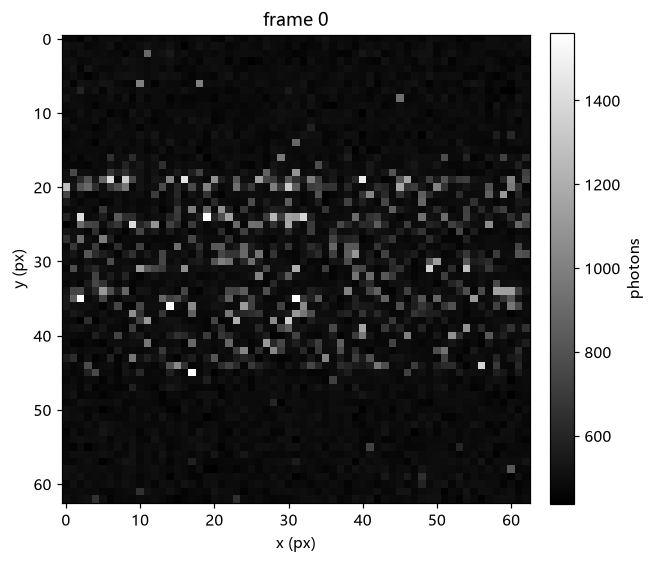

In [6]:
from smlm.viz import show_frames
import numpy as np
show_frames(stack=stack, frames=np.arange(1))

## 信号像素：示意图 · 尾部指数拟合 · 时间/空间相关 (ACF / SCF)


阈值 1300.0 光子 (前半帧峰值, 独立选择) → 信号像素 1618 (40.77%), 背景 2351


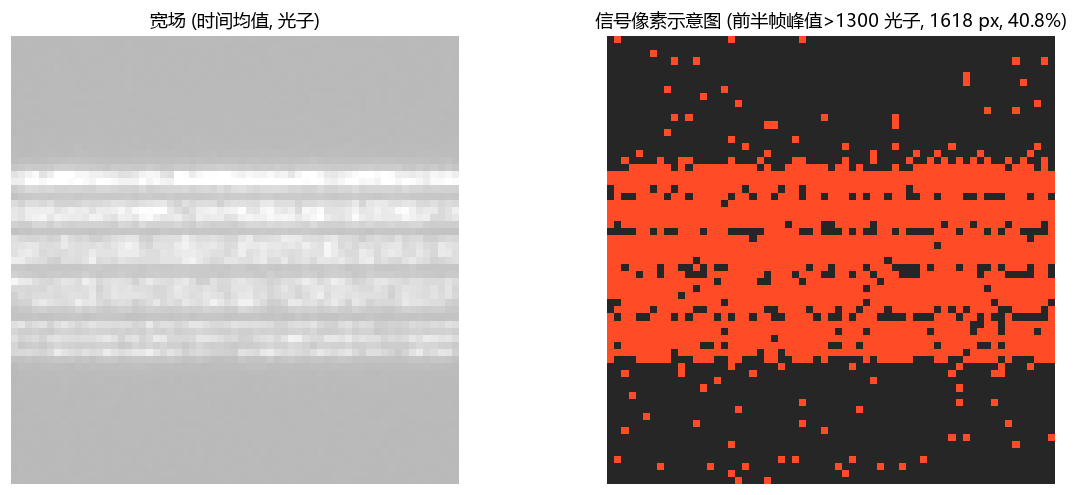

In [7]:
# ============ 信号像素: 统一选择 (放最前, 下游共用) + 空间示意图 ============
# 数据已换算为光子 ((ADU-OFFSET)/GAIN, GAIN=148 e⁻/ADU, OFFSET=486 暗电平)。
# 信号像素选择统一在此完成, FCS/SCF 等下游直接引用 sig_mask/ok, 不再各自重算:
#   · 独立统计量避免选择偏倚: 前一半帧选信号像素, 后一半帧用于分析。
#   · 全程 float64 避免精度损失。
data = stack.data.astype(np.float64)
SIG_THR_ADU = 1300.0                      # 参考阈值 (ADU)
SIG_THR_PHOTON = (SIG_THR_ADU-OFFSET)/GAIN                      # 光子阈值 (1000ADU→3.47 光子, 取整 3)
T = data.shape[0]
Tsel = T // 2
an = data[Tsel:]                          # 分析帧 (后一半)
mu = an.mean(0)                           # 分析帧均值
sig_mask = data[:Tsel].max(0) > SIG_THR_PHOTON   # 信号像素: 前半帧峰值>阈值 (独立选择)
ok = sig_mask & (mu > 0)                  # 分析用信号像素 (显示/统计)
n_sig = int(sig_mask.sum()); n_bg = int((~sig_mask).sum())
print(f"阈值 {SIG_THR_PHOTON:.1f} 光子 (前半帧峰值, 独立选择) → "
      f"信号像素 {n_sig} ({100*n_sig/sig_mask.size:.2f}%), 背景 {n_bg}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
wf = data.mean(0)
axes[0].imshow(wf, cmap="gray", vmin=0, vmax=float(np.percentile(wf, 99)))
axes[0].set_title("宽场 (时间均值, 光子)"); axes[0].axis("off")
ov = np.zeros((*wf.shape, 3), dtype=np.float32)
ov[..., :] = 0.15
ov[sig_mask, 0] = 1.0; ov[sig_mask, 1] = 0.3
axes[1].imshow(ov)
axes[1].set_title(f"信号像素示意图 (前半帧峰值>{SIG_THR_PHOTON:.0f} 光子, {n_sig} px, "
                  f"{100*n_sig/sig_mask.size:.1f}%)")
axes[1].axis("off")
plt.tight_layout(); plt.show()


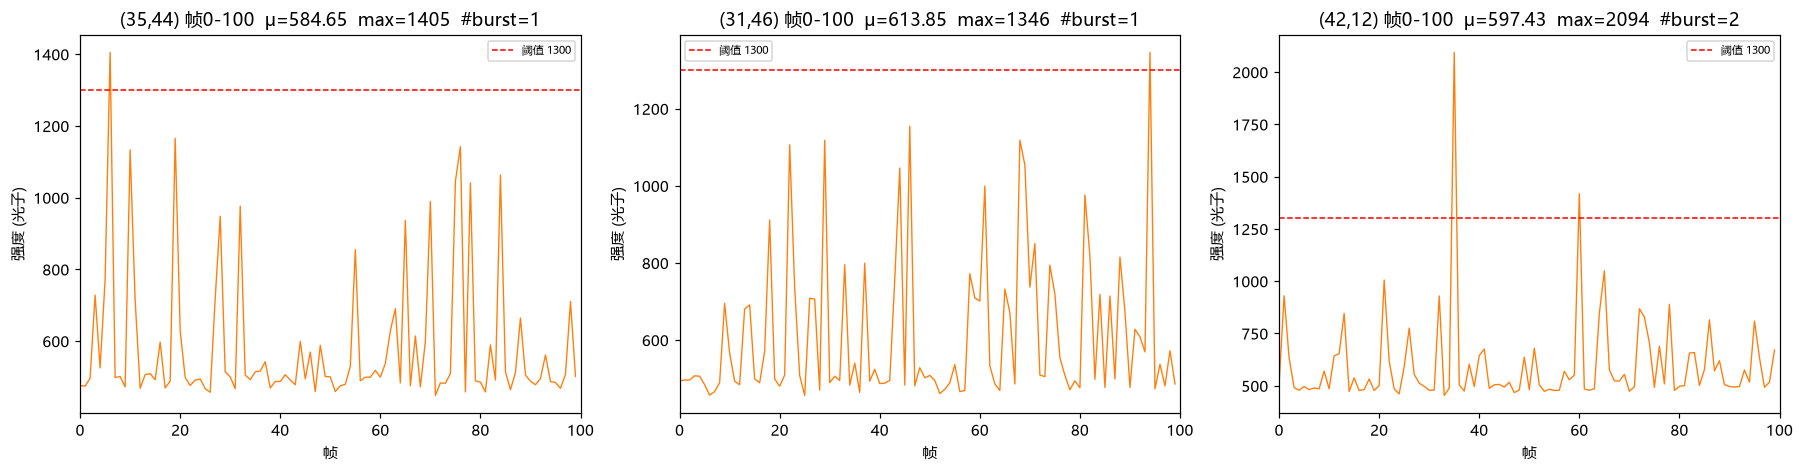

随机信号像素: ['(35,44)', '(31,46)', '(42,12)'] | 显示帧范围: (0, 100)


In [9]:
# --- 3 个随机信号像素的时间 trace (展示闪烁/上冲形态) ---
TRACE_RANGE = (0, 100)          # 显示帧范围 [start, stop), 单位: 帧 (改这里控制时间窗)
rng = np.random.default_rng(0)                    # 固定种子, 可复现
sig_idx = np.flatnonzero(sig_mask)
picks = [np.unravel_index(i, sig_mask.shape)
         for i in rng.choice(sig_idx, size=3, replace=False)]

f0, f1 = TRACE_RANGE
frames = np.arange(f0, f1)                        # x 轴: 帧号 (仅显示窗口内)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.4))
for ax, yx in zip(axes, picks):
    tr = data[f0:f1, yx[0], yx[1]]                # 只取显示窗口内的 trace
    ax.plot(frames, tr, lw=0.9, color="C1")
    ax.axhline(SIG_THR_PHOTON, color="r", ls="--", lw=1, label=f"阈值 {SIG_THR_PHOTON:.0f}")
    ax.set_xlim(f0, f1)
    ax.set_xlabel("帧"); ax.set_ylabel("强度 (光子)")
    ax.set_title(f"({yx[0]},{yx[1]}) 帧{f0}-{f1}  μ={tr.mean():.2f}  "
                 f"max={tr.max():.0f}  #burst={int((tr > SIG_THR_PHOTON).sum())}")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("随机信号像素:", [f"({y},{x})" for y, x in picks], "| 显示帧范围:", TRACE_RANGE)


## EXP FIT

In [ ]:
# ============ 4) 信号部分: Poisson-Gamma (EMCCD) 增益标定 ============
# EMCCD 单像素输出 Δ = I - offset 服从 Poisson-Gamma 复合分布:
#   p(Δ) = Σ_N Pois(N|λ) · [Gamma(Δ; N, c) ⊗ N(0, σ_read)]
#   N=0: 读出噪声高斯峰;  N=1: 指数 Exp(c)=单光子;  N≥2: Gamma(N,c)=多光子
# ★ 两个关键修正 (已在 sim 上验证, 真 c=148.4 恢复到 147.6, σ_read→54e-):
#  ① λ 异质性: 把所有信号像素混合成单一 λ 拟合会把 c 高估 ~15% (混合样本的
#     N≥2 权重 > 单一 Poisson)。改为"按像素时间均值分带", 共享 c 和 σ_read,
#     每带独立 λ 做联合 MLE。
#  ② σ_read 用 e⁻ 表达: 背景像素时间 std 会掺入 EMCCD excess noise, 不是纯
#     读出噪声。把 σ_read 作为自由参数拟合, 由 MLE 自动给出 (sim 真值 56 e⁻)。
SENSITIVITY_E_PER_ADU = 3.37   # sim 的 sensitivity (e-/ADU) → σ_read 报 e⁻; exp 未知留 None
from scipy.stats import poisson, gamma, norm
from scipy.optimize import minimize

data = stack.data.astype(np.float64)

# ---- 1) offset: 低时间方差(=背景)像素的中位 ----
mu_px = data.mean(0); var_px = data.var(0)
bg_mask = var_px < np.percentile(var_px, 5)
offset = float(np.median(mu_px[bg_mask]))
print(f"offset = {offset:.1f} ADU")

# ---- 2) 信号像素: 峰值>阈值, 按时间均值分带 (每带 λ 均匀) ----
sig_mask = data.max(0) > SIG_THR_ADU
rr, cc = np.unravel_index(np.flatnonzero(sig_mask), sig_mask.shape)
mu_sig = data.mean(0)[sig_mask]
K = 5
edges = np.percentile(mu_sig, np.linspace(0, 100, K + 1))
band_samp = []
band_med = []
for k in range(K):
    m = (mu_sig >= edges[k]) & (mu_sig <= edges[k + 1])
    band_med.append(float(np.median(mu_sig[m])))
    s = (data[:, rr[m], cc[m]] - offset).ravel()
    band_samp.append(s[(s > -50) & (s < 4000)])
print(f"信号像素 n={len(mu_sig)}, 分 {K} 带 (带 μ 中位: "
      + " ".join(f"{v:.0f}" for v in band_med) + " ADU)")

# ---- 3) 每带直方图 + 联合 MLE (共享 c,σ_read; 每带独立 λ) ----
edge = np.arange(-100, 4001, 2.0)
hists = [np.histogram(b, bins=edge)[0] for b in band_samp]
ctr = (edge[:-1] + edge[1:]) / 2
sels = [h > 0 for h in hists]

def pg_pdf(lam, c, sigma, dmax=4000, step=2.0, nmax=8):
    dgrid = np.arange(-10 * sigma, dmax + step, step)
    p = np.zeros_like(dgrid, dtype=float)
    nk = int(round(5 * sigma / step))
    k = np.arange(-nk, nk + 1) * step
    kernel = norm.pdf(k, 0, sigma)
    for N in range(nmax + 1):
        w = poisson.pmf(N, lam)
        pN = norm.pdf(dgrid, 0, sigma) if N == 0 else \
             np.convolve(gamma.pdf(dgrid, N, scale=c), kernel, mode="same") * step
        pN = pN / (pN.sum() * step)
        p += w * pN
    return dgrid, p

def nll(theta):
    c, sigma = np.exp(theta[0]), np.exp(theta[1])
    lams = np.exp(theta[2:])
    tot = 0.0
    for lam, h, sel in zip(lams, hists, sels):
        dg, p = pg_pdf(lam, c, sigma)
        pb = np.maximum(np.interp(ctr, dg, p) * 2.0, 1e-14)
        tot -= float((h[sel] * np.log(pb[sel])).sum())
    return tot

th0 = [np.log(150), np.log(16)] + list(np.log(np.linspace(0.1, 1.0, K)))
res = minimize(nll, th0, method="Nelder-Mead",
               options=dict(xatol=1e-4, fatol=0.1, maxiter=8000))
c, sig_read = np.exp(res.x[0]), np.exp(res.x[1])
lams = np.exp(res.x[2:])
n2 = 1 - poisson.pmf(0, lams).mean() - poisson.pmf(1, lams).mean()

print("\n=== 联合分带 Poisson-Gamma MLE (EMCCD 增益标定) ===")
print(f"c (单光子增益)      = {c:.1f} ADU")
if SENSITIVITY_E_PER_ADU:
    print(f"σ_read (读出噪声)   = {sig_read:.1f} ADU = {sig_read*SENSITIVITY_E_PER_ADU:.1f} e⁻")
else:
    print(f"σ_read (读出噪声)   = {sig_read:.1f} ADU  (设 SENSITIVITY_E_PER_ADU 可转 e⁻)")
print(f"offset (偏置)       = {offset:.1f} ADU")
print(f"各带 λ              = " + " ".join(f"{l:.3f}" for l in lams))
print(f"N≥2 多光子事件占比 ≈ {n2:.1%}")

# ---- 4) 验证图: 数据直方图 vs 模型 (所有带叠加) ----
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = plt.cm.viridis(np.linspace(0, 1, K))
for k, (h, lam) in enumerate(zip(hists, lams)):
    dg, p = pg_pdf(lam, c, sig_read)
    ax.stairs(h, edge, fill=True, alpha=0.4, color=colors[k])
    ax.plot(dg, p * len(band_samp[k]) * 2.0, color=colors[k], lw=1.5,
            label=f"带{k+1} λ={lam:.2f}")
ax.set_yscale("log"); ax.set_xlim(0, 800)
ax.set_xlabel("Δ = I - offset (ADU)"); ax.set_ylabel("样本数 (log)")
ax.set_title(f"联合分带 Poisson-Gamma 拟合: c={c:.1f} ADU, σ_read={sig_read:.1f} ADU")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## FCS

In [ ]:
# ============ 2) FCS/相关: G(τ) + 时间/邻域的 corr 与 cov 空间分布 ============
# 信号像素 sig_mask/ok、分析帧 an、均值 mu 已由最前 cell 统一给出 (独立选择, 无偏倚)。
# 归一化口径: σ² ≡ cov[0], corr=cov/σ², G=cov/μ² 同源一致; 全程 float64。
Na = an.shape[0]
L = min(20, Na // 4)
dc = an - mu[None]

# ---- 时间: 逐滞后协方差 cov(τ) = <(I_t-μ)(I_{t+τ}-μ)> ----
cov = np.zeros((L + 1,) + mu.shape, np.float64)
cov[0] = (dc * dc).mean(0)
for tau in range(1, L + 1):
    cov[tau] = (dc[:-tau] * dc[tau:]).mean(0)

sd2 = np.maximum(cov[0], 0.0)                 # σ² ≡ cov[0] (同一 mean 口径)
sd = np.sqrt(sd2)
mu2 = np.maximum(mu * mu, 1e-12)
G = cov / mu2[None]
G0, G1 = G[0], G[1]
cov1 = cov[1]
corr_t = cov1 / np.maximum(sd2, 1e-12)        # ACF(1) = cov(1)/σ²

# ---- 临近像素 (帧内 4 邻域, 时间平均): 互协方差 cov + Pearson 相关 corr ----
cov_nb = np.zeros_like(mu); cnt_nb = np.zeros_like(mu)
corr_nb = np.zeros_like(mu); cnt_c = np.zeros_like(mu)
c = (dc[:, :, :-1] * dc[:, :, 1:]).mean(0)                      # 右邻
cov_nb[:, :-1] += c; cnt_nb[:, :-1] += 1
corr_nb[:, :-1] += c / (sd[:, :-1] * sd[:, 1:] + 1e-12); cnt_c[:, :-1] += 1
c = (dc[:, :, 1:] * dc[:, :, :-1]).mean(0)                      # 左邻
cov_nb[:, 1:] += c; cnt_nb[:, 1:] += 1
corr_nb[:, 1:] += c / (sd[:, 1:] * sd[:, :-1] + 1e-12); cnt_c[:, 1:] += 1
c = (dc[:, :-1, :] * dc[:, 1:, :]).mean(0)                      # 下邻
cov_nb[:-1, :] += c; cnt_nb[:-1, :] += 1
corr_nb[:-1, :] += c / (sd[:-1, :] * sd[1:, :] + 1e-12); cnt_c[:-1, :] += 1
c = (dc[:, 1:, :] * dc[:, :-1, :]).mean(0)                      # 上邻
cov_nb[1:, :] += c; cnt_nb[1:, :] += 1
corr_nb[1:, :] += c / (sd[1:, :] * sd[:-1, :] + 1e-12); cnt_c[1:, :] += 1
cov_nb = cov_nb / np.maximum(cnt_nb, 1)
corr_nb = corr_nb / np.maximum(cnt_c, 1)

n_ok = int(ok.sum())
print(f"信号像素 {n_ok} (独立选择): μ 中位={np.median(mu[ok]):.3f}")
print(f"时间: G(0)中位={np.median(G0[ok]):.3f} (泊松1/μ={np.median(1/np.maximum(mu[ok],1e-9)):.3f})  "
      f"G(1)中位={np.median(G1[ok]):.4f}  corr(ACF1)中位={np.median(corr_t[ok]):.4f}  "
      f"cov(1)中位={np.median(cov1[ok]):.4f}")
print(f"邻域: corr(SCF)中位={np.median(corr_nb[ok]):.3f}  cov 中位={np.median(cov_nb[ok]):.4f}")

# --- G(τ) vs τ 曲线 (仅信号像素) ---
taus = np.arange(L + 1)
gm = np.nanmedian(G[:, ok], axis=1)
glo = np.nanpercentile(G[:, ok], 25, axis=1)
ghi = np.nanpercentile(G[:, ok], 75, axis=1)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.fill_between(taus, glo, ghi, alpha=0.2, label="IQR")
ax.plot(taus, gm, "o-", lw=2, label="信号像素 G(τ) 中位")
ax.axhline(0, color="k", ls="--", lw=1)
ax.set_xlabel("滞后 τ (帧)"); ax.set_ylabel("G(τ) = cov(τ)/μ²")
ax.set_title("FCS: G(τ) 随滞后帧变化 (信号像素)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# --- 空间分布图 (2×3): 只显示信号像素(ok), 其余为 NaN(空白) ---
def _show(ax, arr, mask, cmap, sym=False, p=99.5, title=""):
    if sym:
        va = float(np.nanpercentile(np.abs(arr[mask]), p))
        im = ax.imshow(np.where(mask, arr, np.nan), cmap=cmap, vmin=-va, vmax=va)
    else:
        im = ax.imshow(np.where(mask, arr, np.nan), cmap=cmap,
                       vmin=0, vmax=float(np.nanpercentile(arr[mask], p)))
    ax.set_title(title, fontsize=9); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

fig, axes = plt.subplots(2, 3, figsize=(16.5, 9.2))
_show(axes[0][0], G0, ok, "hot", False, 99.5, "G(0) = σ²/μ² (时间)")
_show(axes[0][1], G1, ok, "hot", False, 99.5, "G(1) = cov(1)/μ² (时间)")
_show(axes[0][2], corr_t, ok, "RdBu_r", True, 99.5, "corr(时间) = cov(1)/σ² = ACF(1)")
_show(axes[1][0], cov1, ok, "RdBu_r", True, 99.5, "cov(时间) = cov(1)")
_show(axes[1][1], corr_nb, ok, "RdBu_r", True, 99.5, "corr(邻域) = SCF (Pearson)")
_show(axes[1][2], cov_nb, ok, "RdBu_r", True, 99.5, "cov(邻域) = 帧内互协方差")
plt.tight_layout(); plt.show()

# --- 直方图 (与上图同布局): 只统计信号像素(ok) ---
def _hist(ax, v, sym=False, title=""):
    if sym:
        va = float(np.nanpercentile(np.abs(v), 99.5))
        vv = np.clip(v, -va, va)
    else:
        va = float(np.nanpercentile(v, 99))
        vv = np.clip(v, 0, va)
    h, e = np.histogram(vv, bins=80)
    ax.stairs(h, e, fill=True)
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.set_xlabel("值"); ax.set_ylabel("像素数")
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(16.5, 9.2))
_hist(axes[0][0], G0[ok], False, "G(0) 分布 (信号像素)")
_hist(axes[0][1], G1[ok], True, "G(1) 分布 (信号像素)")
_hist(axes[0][2], corr_t[ok], True, "corr(时间) 分布 (信号像素)")
_hist(axes[1][0], cov1[ok], True, "cov(时间) 分布 (信号像素)")
_hist(axes[1][1], corr_nb[ok], True, "corr(邻域) 分布 (信号像素)")
_hist(axes[1][2], cov_nb[ok], True, "cov(邻域) 分布 (信号像素)")
plt.tight_layout(); plt.show()


In [ ]:
# ============ 3) 帧内空间相关 (FCS 式归一化): 每像素 × 4 邻域 ============
# 使用最前 cell 统一给出的分析帧 an / 均值 mu / 信号像素 ok。
# 与时间 FCS G=cov/μ² 一致, 空间互相关按"均值乘积"归一化 (÷μ_i μ_j)。
dc = an - mu[None]
Hh, Ww = mu.shape
sc = np.zeros((Hh, Ww), np.float64); cnt = np.zeros((Hh, Ww), np.float64)
c = (dc[:, :, :-1] * dc[:, :, 1:]).mean(0)                      # 右邻
sc[:, :-1] += c / (mu[:, :-1] * mu[:, 1:] + 1e-12); cnt[:, :-1] += 1
c = (dc[:, :, 1:] * dc[:, :, :-1]).mean(0)                      # 左邻
sc[:, 1:] += c / (mu[:, 1:] * mu[:, :-1] + 1e-12); cnt[:, 1:] += 1
c = (dc[:, :-1, :] * dc[:, 1:, :]).mean(0)                      # 下邻
sc[:-1, :] += c / (mu[:-1, :] * mu[1:, :] + 1e-12); cnt[:-1, :] += 1
c = (dc[:, 1:, :] * dc[:, :-1, :]).mean(0)                      # 上邻
sc[1:, :] += c / (mu[1:, :] * mu[:-1, :] + 1e-12); cnt[1:, :] += 1
sc = sc / np.maximum(cnt, 1)

valid = cnt > 0
v = sc[ok & valid]
n_v = int((ok & valid).sum())
print(f"帧内空间 FCS (÷μ_iμ_j, 信号像素 n={n_v}): 中位={np.median(v):.3f}  "
      f"IQR=[{np.percentile(v,25):.3f}, {np.percentile(v,75):.3f}]  "
      f"p0.5-p99.5=[{np.percentile(v,0.5):.2f}, {np.percentile(v,99.5):.2f}]")
print("注: 逐像素 μ 极小 → ÷μ² 会放大小均值像素噪声, 存在极端离群值, 以中位数为准。")


## 传统 SOFI: n 阶累积量

SOFI 对每个像素计算信号的时间累积量：

$$\kappa_m(\mathbf r) \propto \sum_k \varepsilon_k^m\, U^m(\mathbf r - \mathbf r_k)$$

即输出 PSF 是 $U^m$（宽度 $\div\sqrt{m}$）。**阶数越高分辨率越高**。

这里用重构后的 `smlm.imgprocess`：`CumulantSofit` 是 SOFI 核心（`Transform` 子类），上采样通过显式的 `FourierUpsample` 阶段接入 `Pipeline`——所有环节都是 `ImageStack` 进、`ImageStack` 出。

In [ ]:
# 加载超分辨 ground truth（仅 simulate 需要; paperdata 无 GT 则自动跳过）
GT_AVAILABLE = bool(GT_PATH) and os.path.exists(GT_PATH)
gt_sres = None
gt_ps = PIXEL_NM / 16                          # ≈6.67 nm/px（与 GT 渲染一致）
if GT_AVAILABLE:
    gt_sres = tifffile.imread(GT_PATH).astype(np.float64)  # 实际形状以文件为准
    print("GT:", gt_sres.shape, "| 有效像素:", gt_ps, "nm/px | 范围: [%.1f, %.1f]" % (gt_sres.min(), gt_sres.max()))
    # GT 先与 EC 有效宽度高斯核卷积 → 公平对比参考 (GT 是 ~10nm 点, 而 RIED/SOFI 有效PSF≈POST_PSF_FWHM_NM)
    sigma_gt = POST_PSF_FWHM_NM / (2 * np.sqrt(2 * np.log(2))) / gt_ps   # 高斯 σ (GT 像素)
    gt_sres = scipy.ndimage.gaussian_filter(gt_sres, sigma=sigma_gt)
    print("→ GT 已用 FWHM=%.0fnm 高斯卷积 (模糊到 EC 有效宽度, 作为渲染/对比参考)" % POST_PSF_FWHM_NM)
else:
    print("⚠️ 无 GT（paperdata 或无文件）—— 对比图将不含 GT / 剖面。")


def crop_extent(z, ps, roi_y, roi_x, H0, W0):
    """按宽场像素 ROI 裁剪图像 z，返回 (裁剪块, nm extent)。

    物理坐标以 z 自身网格中心为原点：ext = (left, right, bottom, top) nm。
    各 stage 网格/像素尺寸不同，用各自 sy=z.shape[0]/H0、sx=z.shape[1]/W0
    换算出同一物理区域（行按 H0、列按 W0 分别缩放，支持非方形视场）。
    """
    sy = z.shape[0] / H0
    sx = z.shape[1] / W0
    y0, y1 = int(roi_y[0] * sy), int(roi_y[1] * sy)
    x0, x1 = int(roi_x[0] * sx), int(roi_x[1] * sx)
    c = z[y0:y1, x0:x1]
    h, w = z.shape[:2]
    ext = ((x0 - w / 2) * ps, (x1 - w / 2) * ps,
           (h / 2 - y1) * ps, (h / 2 - y0) * ps)           # left,right,bottom,top (nm)
    return c, ext


def gt_similarity(z):
    """把图像 z 对齐到 GT 网格，返回与 GT 的相似性指标 dict（仅 simulate 用）。

    指标：Pearson r / SSIM / PSNR(dB) / NRMSE。z 与 GT 假设覆盖同一 FOV，
    用 map_coordinates 重采样到 GT 网格（gt_sres.shape[0]²）后比较。
    """
    from skimage.metrics import structural_similarity as ssim

    def _resample(img, n):
        h, w = img.shape
        yy = (np.arange(n) + 0.5) * h / n - 0.5
        xx = (np.arange(n) + 0.5) * w / n - 0.5
        YY, XX = np.meshgrid(yy, xx, indexing="ij")
        return scipy.ndimage.map_coordinates(img, (YY, XX), order=1,
                                             mode="constant", cval=0.0)

    def _norm01(a):
        a = a - a.min(); mx = a.max()
        return a / mx if mx > 0 else a

    def _pearson(a, b):
        a = a - a.mean(); b = b - b.mean()
        return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-12))

    def _psnr(a01, b01):
        mse = float(np.mean((a01 - b01) ** 2))
        return float(10 * np.log10(1.0 / mse)) if mse > 0 else float('inf')

    a = _resample(np.asarray(z, dtype=np.float64), gt_sres.shape[0])
    an, gn = _norm01(a), _norm01(gt_sres)
    return {"Pearson r": _pearson(a, gt_sres),
            "SSIM": ssim(an, gn, data_range=1.0),
            "PSNR (dB)": _psnr(an, gn),
            "NRMSE": float(np.sqrt(np.mean((an - gn) ** 2)))}

In [ ]:
# 跳过光漂白校正（数据已平稳）; 若需校正可改回: stack_bc = BleachCorrect("mono_exp")(stack)
stack_bc = stack
print("stack_bc:", stack_bc.data.shape, "| pixel_size:", stack_bc.pixel_size, "nm/px")

In [ ]:
# 传统 n 阶累积量 SOFI: Pipeline(FourierUpsample(2), CumulantSofit(order=m))
orders = [2, 3]
sofi_res = {}
for m in orders:
    img = Pipeline(FourierUpsample(2, lateral=True,take_abs = True),
                   CumulantSofit(order=m, subseq=250))(stack_bc)
    sofi_res[m] = img.data[0]
    print(f"order {m}: {img.data.shape}  range [{img.data.min():.3g}, {img.data.max():.3g}]"
          f"  |abs| max {np.abs(img.data).max():.3g}（显示时取 abs 以去除负值）")


In [ ]:
# 传统 SOFI 对比（simulate 显示 GT + 截面 profile；paperdata 仅并排 + 中央放大）
ps_up = stack_bc.pixel_size / 2                       # 2× 上采样后的有效像素 (nm)
wf2 = FourierUpsample(2, taper=False)(stack_bc).data.mean(0)     # 对齐到 2× 网格

# 显示用: n 阶累积量输出含负值(符号起伏/噪声/伪影), 统一取 abs 防止负值影响显示与剖面
sofi_show = {m: np.abs(sofi_res[m]) for m in orders}

ncol = (2 if GT_AVAILABLE else 1) + len(orders)
fig, axes = plt.subplots(1, ncol, figsize=(4.5 * ncol, 4.5))
i0 = 0
if GT_AVAILABLE:
    axes[0].imshow(gt_sres, cmap="hot", vmax=np.percentile(gt_sres, 99.8),
                   interpolation="nearest", aspect="equal")
    axes[0].set_title("GT (模糊到EC)"); axes[0].axis("off")
    i0 = 1
axes[i0].imshow(stack_bc.data.mean(0), cmap="gray", interpolation="nearest", aspect="equal")
axes[i0].set_title("Widefield (mean)"); axes[i0].axis("off")
for ax, m in zip(axes[i0 + 1:], orders):
    plot_sofi(sofi_show[m], ax=ax, title=f"SOFI order {m} (abs)")
plt.tight_layout(); plt.show()

# 线剖面（仅 simulate 展示, x 轴 = 距中心 nm）
if SHOW_PROFILE:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    if GT_AVAILABLE:
        line_profile(gt_sres, row=gt_sres.shape[0] // 2, ax=ax, label="GT (模糊到EC)", pixel_size=gt_ps)
    line_profile(wf2, row=wf2.shape[0] // 2, ax=ax, label="widefield", pixel_size=ps_up)
    for m in orders:
        line_profile(sofi_show[m], row=sofi_show[m].shape[0] // 2, ax=ax,
                     label=f"order {m}", pixel_size=ps_up)
    ax.set_title("line profile: 阶数越高 PSF 越窄" + ("（GT 为真值位置）" if GT_AVAILABLE else "")); ax.legend()
    plt.tight_layout(); plt.show()

# 局部放大（中央 50% 区域），统一按 nm 物理坐标对齐。
# 注意: stack_bc.data 是 (T, H, W), H0/W0 取图像高/宽 (px), 不是帧数!
W0 = stack_bc.data.shape[2]      # 宽场宽 (px)
H0 = stack_bc.data.shape[1]      # 宽场高 (px)
roi_y, roi_x = (H0 // 4, 3 * H0 // 4), (W0 // 4, 3 * W0 // 4)   # 中央 50% 区域（自适应）

sofi_imgs = []
if GT_AVAILABLE:
    sofi_imgs.append(("GT (模糊到EC)", *crop_extent(gt_sres, gt_ps, roi_y, roi_x, H0, W0)))
sofi_imgs += [("widefield", *crop_extent(wf2, ps_up, roi_y, roi_x, H0, W0))] + \
             [(f"order {m} (abs)", *crop_extent(sofi_show[m], ps_up, roi_y, roi_x, H0, W0)) for m in orders]
fig, axes = plt.subplots(1, len(sofi_imgs), figsize=(4.6 * len(sofi_imgs), 4.6))
for ax, (nm, c, ext) in zip(axes, sofi_imgs):
    v = np.percentile(c, 99.8)
    ax.imshow(np.clip(c, 0, v), cmap="hot", interpolation="nearest",
              aspect="equal", extent=ext)
    ax.set_title(f"{nm}  {c.shape[0]}×{c.shape[1]}"); ax.set_xlabel("x (nm)")
fig.suptitle("局部放大（GT / SOFI (abs)，nm 对齐）")
plt.tight_layout(); plt.show()

# 与 GT 的相似性评估（仅 simulate）
if SHOW_PROFILE and GT_AVAILABLE:
    print("=== 与 GT 的相似性（SOFI (abs)，simulate）===")
    rows = [("widefield", wf2)] + [(f"SOFI order {m} (abs)", sofi_show[m]) for m in orders]
    sim = {n: gt_similarity(z) for n, z in rows}
    print(f"{'方法':<20}{'Pearson r':>10}{'SSIM':>8}{'PSNR(dB)':>10}{'NRMSE':>8}")
    for n in sim:
        print(f"{n:<20}{sim[n]['Pearson r']:>10.4f}{sim[n]['SSIM']:>8.3f}"
              f"{sim[n]['PSNR (dB)']:>10.2f}{sim[n]['NRMSE']:>8.4f}")
    fig, ax = plt.subplots(figsize=(8, 4))
    xn = list(sim)
    ax.bar(np.arange(len(xn)), [sim[n]["Pearson r"] for n in xn], color="C0")
    ax.axhline(1, color='r', ls='--', lw=1)
    ax.set_xticks(np.arange(len(xn))); ax.set_xticklabels(xn, rotation=15)
    ax.set_ylabel("Pearson r"); ax.set_title("与 GT 的 Pearson 相关（SOFI (abs)，↑）")
    plt.tight_layout(); plt.show()


## RIED: 0-lag 二阶累积量 —— 逐步加长 pipeline

RIED 的核心是**熵加权相关** `EC = 熵图 × 交叉累积量`：

- **交叉累积量**（`xc_cumulant`）：0-lag 二阶统计量，用"偏移均值差 × 相邻像素乘积"
  提取涨落信息，并生成 **2× 虚拟像素网格**；
- **熵图**（`entromap`）：2×2 邻域时间轨迹的交叉熵，用于识别真正的发光体/抑制背景。

下面**逐步加长 pipeline**，每一级都在上一级基础上追加一步，并记录尺寸演进
（裁剪后视场为 255×255，每级 2× → 255 → 510 → 1020）：

| Stage | 追加内容 | 目的 | 输出尺寸 / 像素 |
|---|---|---|---|
| 宽场 | 时间均值 | 原始对照 | 255×255 / 106.6 nm |
| P1 | 高斯预滤波 | 抑制高频采样噪声 | 255×255 / 106.6 nm |
| P2 | + 傅里叶上采样 ×2 → RL3D 预反卷积 | 加密网格 + 增强涨落 | 510×510 / 53.3 nm |
| P3 | + 0-lag 二阶累积量 (xc_cumulant) | 提取涨落信息（分辨率提升核心） | 1020×1020 / 26.7 nm |
| P4 | + 熵加权 (entromap × 累积量) | 抑制背景、突出发光体 | 1020×1020 / 26.7 nm |
| P5 | + 后置稀疏反卷积 (split-Bregman TV+L1) | 进一步锐化、去伪影 | 1020×1020 / 26.7 nm |

> **尺寸注意**：各级网格/像素尺寸不同（106.6 → 53.3 → 26.7 nm/px），
> 所以下面所有可视化都按**物理坐标 (nm) 对齐**：ROI 裁剪与线剖面都用
> 各 stage 自身的网格索引换算到同一物理区域，而不是按像素数直接对齐。

In [ ]:
# RIED: 0-lag 二阶累积量 —— 逐步加长 pipeline（参数见顶部配置）
ried_stack = Dehotpixel()(SelectFrames(stop=200)(stack_bc))   # 短栈 + 热点去除
print("ried_stack:", ried_stack.data.shape, "| pixel:", ried_stack.pixel_size, "nm/px")

stages = {}
# P1: 高斯预滤波（栈 → 取时间均值作为单张对照）
stages["P1: 高斯滤波"] = Pipeline(GaussianFilter(0.5))(ried_stack).data.mean(0)
print("P1:", stages["P1: 高斯滤波"].shape)

# P2: + 傅里叶上采样 ×2 → RL3D 预反卷积
# PSF 用 scalar_psf（Generate_PSF 等价的标量衍射积分），网格像素 = 实际数据像素/2。
# PSF 核不能大于被反卷积的图像网格；小视场时自动封顶到网格尺寸（保持奇数核）。
# ⚠️ 迭代数统一用配置 RL_ITERS（exp/paperdata=4, simulate=15）。
#    RL 迭代过多会过拟合噪声——已量化验证: 合成图上 4 次最优(相对+24dB)、5 次略差、
#    15 次明显失真; exp 数据 P2 的梯度能量 grad 从 it=4 的 8.4 涨到 it=15 的 15.1。
#    P3/P4 曾硬编码 15 → 即"失真很多"的根源; 这里改用 RL_ITERS。
n_rl = ried_stack.data.shape[2] * 2                 # RL3D 输入网格（×2 上采样后）
n_psf1 = min(PSF_SIZE, n_rl)
n_psf1 = n_psf1 - 1 if n_psf1 % 2 == 0 else n_psf1   # 保持奇数核
psf1 = scalar_psf((n_psf1, n_psf1), ried_stack.pixel_size / 2, NA, WAVELENGTH)
stages["P2: +上采样+RL"] = Pipeline(GaussianFilter(0.5),
                                    FourierUpsample(2, taper=False, lateral=True,take_abs = True),
                                    RL3D(psf1, iterations=RL_ITERS)
                                    )(ried_stack).data.mean(0)
print("P2:", stages["P2: +上采样+RL"].shape)

In [ ]:
# P3: + 0-lag 二阶累积量（xc_cumulant，无熵加权）
stages["P3: RIEDSOfit (sub=1)"] = Pipeline(GaussianFilter(0.5),
              FourierUpsample(2, taper=False, lateral=True,take_abs = True),
              RL3D(psf1, iterations=RL_ITERS), RiedSofit(subfactor=1, entropy=True))(ried_stack).data[0]
print("P3:", stages["P3: RIEDSOfit (sub=1)"].shape)

In [ ]:
# P4: + 熵加权（entromap × xc_cumulant）
stages["P4: RIEDSOfit (sub=0.5)"] = Pipeline(GaussianFilter(0.5), FourierUpsample(2, lateral=True,take_abs = True),
                    RL3D(psf1, iterations=RL_ITERS),
                    RiedSofit(subfactor=0.5, entropy=True),
                    )(ried_stack).data[0]

print("P4:", stages["P4: RIEDSOfit (sub=0.5)"].shape)


#ried_out = Pipeline(GaussianFilter(0.7), FourierUpsample(2, lateral=True),
                    #RL3D(psf_rl, iterations=15),
                    #CumulantSofit(order=2, subseq=250, lags=(0,0)), FourierUpsample(2, lateral=True),
                    #RL3D(psf_post, iterations=15))(ried_stack).data[0]

#Pipeline(GaussianFilter(0.7),
#              FourierUpsample(2, taper=False, lateral=True),
 #             RL3D(psf1, iterations=RL_ITERS), RiedSofit(subfactor=SUBFACTOR, entropy=True, minv=ENTROPY_MINV))(ried_stack).data[0]

In [ ]:
# P5: + 后置稀疏反卷积（split-Bregman TV+L1，末段 RL）
# RIED 后置 PSF 在更细网格 (pixel/(finter*finter2)/2) 上生成，scalar_psf 同 matlab。
# 同样封顶到 SparseDeconv 输入网格（×4 上采样后），保持奇数核。
n_post = ried_stack.data.shape[2] * 4               # SparseDeconv 输入网格（×4 后）
n_psf2 = min(PSF_SIZE, n_post)
n_psf2 = n_psf2 - 1 if n_psf2 % 2 == 0 else n_psf2   # 保持奇数核
# 后置核 = 与 EC 有效宽度匹配的高斯核 (FWHM=POST_PSF_FWHM_NM≈90nm) 替代过宽的 scalar PSF
#   (matlab 默认 scale=1 不缩小 post-PSF → 过度锐化; 这里显式用匹配宽度, 保留 SparseDeconv 流程)
yy2, xx2 = np.mgrid[0:n_psf2, 0:n_psf2]
r2 = np.hypot(xx2 - n_psf2 // 2, yy2 - n_psf2 // 2) * (ried_stack.pixel_size / 4)
sigma2 = POST_PSF_FWHM_NM / (2 * np.sqrt(2 * np.log(2)))
psf2 = np.exp(-0.5 * (r2 / sigma2) ** 2)
psf2 = (psf2 / psf2.sum()).astype(np.float32)
post = SparseDeconv(psf2, fidelity=150, sparsity=0.2, iter_bregman=100, iterations=10)
stages["P5: +后置反卷积"] = Pipeline(GaussianFilter(0.5),
              FourierUpsample(2, taper=False, lateral=True,take_abs = True),
              RL3D(psf1, iterations=RL_ITERS), RiedSofit(subfactor=0.5, entropy=True, minv=ENTROPY_MINV),
                                     post)(ried_stack).data[0]
print("P5:", stages["P5: +后置反卷积"].shape)

In [ ]:
# RIED 对比：全图总览 + 局部放大 + (simulate) 截面 profile + GT + 相似性评估
names = (["GT (模糊到EC)"] if GT_AVAILABLE else []) + ["宽场(mean)"] + list(stages)
imgs  = ([gt_sres] if GT_AVAILABLE else []) + [ried_stack.data.mean(0)] + list(stages.values())
# 注意: ried_stack.data 是 (T, H, W), W0/H0 取图像宽/高 (px), 不是帧数!
W0, H0 = ried_stack.data.shape[2], ried_stack.data.shape[1]
ps_wide = ried_stack.pixel_size
stage_ps = ([gt_ps] if GT_AVAILABLE else []) + \
           [ps_wide * W0 / z.shape[1] for z in (imgs[1:] if GT_AVAILABLE else imgs)]   # 各 stage 有效像素 (nm/px)

def full_extent(z, ps):
    h, w = z.shape[:2]
    return ((-w/2)*ps, (w/2)*ps, (-h/2)*ps, (h/2)*ps)   # left,right,bottom,top (nm)

# 全图总览（同一物理视场，nm 对齐）
fig, axes = plt.subplots(1, len(imgs), figsize=(3.8*len(imgs), 3.8))
for ax, name, z, ps in zip(axes, names, imgs, stage_ps):
    v = np.percentile(z, 99.8)
    ax.imshow(np.clip(z, 0, v), cmap="hot", interpolation="nearest",
              aspect="equal", extent=full_extent(z, ps))
    ax.set_title(f"{name}\n{z.shape[0]}×{z.shape[1]} · {ps:.1f} nm/px", fontsize=9)
    ax.axis("off")
fig.suptitle("全图总览（GT + 各级，同一物理视场，nm 对齐；网格越密 = 有效像素越小）")
plt.tight_layout(); plt.show()

# ---- 局部放大（中央 50% 区域，自适应），GT 与各 stage 按 nm 对齐 ----
roi_y, roi_x = (H0 // 4, 3 * H0 // 4), (W0 // 4, 3 * W0 // 4)

def crop_and_extent(z, ps):
    sy = z.shape[0] / H0
    sx = z.shape[1] / W0
    y0, y1 = int(roi_y[0]*sy), int(roi_y[1]*sy)
    x0, x1 = int(roi_x[0]*sx), int(roi_x[1]*sx)
    c = z[y0:y1, x0:x1]
    h, w = z.shape[:2]
    ext = ((x0-w/2)*ps, (x1-w/2)*ps, (h/2-y1)*ps, (h/2-y0)*ps)   # left,right,bottom,top (nm)
    return c, ext

fig, axes = plt.subplots(1, len(imgs), figsize=(4.8*len(imgs), 4.8))
for ax, name, z, ps in zip(axes, names, imgs, stage_ps):
    c, ext = crop_and_extent(z, ps)
    v = np.percentile(c, 99.8)
    ax.imshow(np.clip(c, 0, v), cmap="hot", interpolation="nearest",
              aspect="equal", extent=ext)
    ax.set_title(f"{name}  {c.shape[0]}×{c.shape[1]}", fontsize=9)
    ax.set_xlabel("x (nm)")
fig.suptitle("局部放大（GT + 各级，同一物理区域，nm 对齐）")
plt.tight_layout(); plt.show()

# 截面 profile（仅 simulate，x 轴 = 距中心 nm，GT 加粗作真值参考）
if SHOW_PROFILE:
    band_px = 15                              # 中心行上下各 15 个宽场像素做平均
    y_mid = (roi_y[0] + roi_y[1]) / 2
    x_lo = (roi_x[0] - W0 / 2) * ps_wide      # ROI 左边界 nm
    x_hi = (roi_x[1] - W0 / 2) * ps_wide      # ROI 右边界 nm

    fig, ax = plt.subplots(figsize=(11, 5))
    for name, z, ps in zip(names, imgs, stage_ps):
        s = z.shape[1] / W0
        r0, r1 = int((y_mid - band_px) * s), int((y_mid + band_px) * s) + 1
        p = z[max(r0, 0):r1].mean(0)                          # 竖向平均 -> 1D 剖面
        p = (p - p.min()) / (p.max() - p.min() + 1e-12)       # min-max 归一化
        x = (np.arange(len(p)) - len(p) / 2) * ps             # 距中心 nm
        ax.plot(x, p, label=name, lw=2.0 if name == "GT (模糊到EC)" else 0.9,
                alpha=1.0 if name == "GT (真值)" else 0.85)
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel("x (nm from center)")
    ax.set_ylabel("intensity (normalized)")
    ax.set_title(f"line profile（±{band_px}px band 平均，x 限 {x_lo/1000:.1f}–{x_hi/1000:.1f} μm，GT 真值）")
    ax.legend(ncol=2, fontsize=8)
    plt.tight_layout(); plt.show()

# 与 GT 的相似性评估（仅 simulate，逐级接近程度）
if SHOW_PROFILE and GT_AVAILABLE:
    print("=== 各 stage 与 GT 的相似性（RIED，simulate）===")
    sim = {n: gt_similarity(z) for n, z in zip(names, imgs)}
    print(f"{'stage':<16}{'Pearson r':>10}{'SSIM':>8}{'PSNR(dB)':>10}{'NRMSE':>8}")
    for n in names:
        pv = sim[n]['PSNR (dB)']
        psnr_s = "  inf " if np.isinf(pv) else f"{pv:8.2f}"
        print(f"{n:<16}{sim[n]['Pearson r']:>10.4f}{sim[n]['SSIM']:>8.3f}"
              f"{psnr_s}{sim[n]['NRMSE']:>8.4f}")
    xf = np.arange(len(names))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].bar(xf, [sim[n]["Pearson r"] for n in names], color="C0")
    axes[0].axhline(1, color='r', ls='--', lw=1)
    axes[0].set_xticks(xf); axes[0].set_xticklabels(names, rotation=30, fontsize=8)
    axes[0].set_ylabel("Pearson r"); axes[0].set_title("与 GT 的 Pearson 相关（↑）")
    axes[1].bar(xf, [sim[n]["SSIM"] for n in names], color="C1")
    axes[1].axhline(1, color='r', ls='--', lw=1)
    axes[1].set_xticks(xf); axes[1].set_xticklabels(names, rotation=30, fontsize=8)
    axes[1].set_ylabel("SSIM"); axes[1].set_title("与 GT 的 SSIM（↑）")
    plt.tight_layout(); plt.show()

### 小结

**顶部配置区**统一管理两套参数（改 `DATA_MODE` 即可切换）：
- `simulate`：仿真圆环数据（光子、相机换算）、显示 GT + 截面 profile；
- `paperdata`：真实 ECL 图（保持 ADU，对齐 matlab）、不显示 profile/GT；
- `paperdata`：对齐 matlab demo.m 参数（NA=1.42, λ=517, subfactor=0.5, fidelity=150, sparsity=5, iter2=5, PSF 129×129, RL_ITERS=4, POST_PSF≈220nm）；
- `simulate`：python 默认（subfactor=1.0, RL_ITERS=4, POST_PSF≈90nm）。
- 两套参数都含 `RL_ITERS`（预反卷积 RL 迭代）与 `POST_PSF_FWHM_NM`（后置核=EC 有效宽度高斯）。

**保留内容**：
- 传统 2/3 阶累积量 SOFI（`CumulantSofit`）+ 对比；
- RIED 逐步加长 pipeline（P1→P5）：高斯预滤波 → 上采样×2+RL3D → 0-lag 二阶累积量（xc_cumulant）→ 熵加权（entromap×累积量）→ 后置稀疏反卷积（split-Bregman TV+L1）+ 对比；
- 与 matlab 超分辨图（tirf/RIEDrecon）的一致性对比。

**尺寸处理**：各级有效像素不同，可视化一律按 **nm 物理坐标**对齐（ROI 裁剪与线剖面先换算到各级自身网格，再用各自像素尺寸还原为 nm）。

**架构**：所有环节都是 `ImageStack` 进出的 `Transform`；上采样、反卷积、SOFI/RIED 核心都收敛在 `smlm.imgprocess`。PSF 统一用 `scalar_psf`（`Generate_PSF` 等价标量衍射积分）。

> 注：真实 RIED 还含可选的 wavelet 离焦信号去除（CL/BL 用）与 `gamma` 强度校正；需要逐像素对拍 matlab 时可按需补上。